# Phase 11 — Final Test Evaluation

**Notebook:** `10_evaluation.ipynb`
**Project:** Physics-Informed GAT for Diabetic Foot Plantar Thermography (dual-branch architecture)

---

## 🔒 THIS NOTEBOOK TOUCHES THE TEST SET FOR THE FIRST AND ONLY TIME 🔒

`test_loader` has **not** been accessed by any previous phase (1–10). This notebook is meant
to be run **ONCE** as the final, unbiased check on the trained primary model.

- Do **NOT** use anything observed on test here to further tune the model, the decision
  threshold, or any hyperparameter.
- If these results suggest changes are needed, those changes must be made and validated using
  **ONLY train/val** (repeating Phases 8–10), followed by **one fresh Phase 11 re-run** as the
  new final check.
- Everything below this point treats the val-derived threshold as fixed and the test set as
  touched exactly once.

---

### What this notebook does, in order

1. Setup — load data, the trained primary checkpoint, and its recorded config.
2. Val reconfirmation — a sanity check only (val was already used in Phase 10).
3. Threshold optimization on **val only** (Youden's J), fixed before touching test.
4. Final test evaluation — plain (point-estimate) forward pass.
5. Final test evaluation — MC-Dropout (T=30), the first *meaningful* uncertainty result.
6. Confusion matrices + ROC curve.
7. Subject-level aggregation (the clinically meaningful unit).
8. Uncertainty-stratified rejection curve.
9. Error analysis table.
10. Save results (`results/`).
11. Final summary.


## Section 1 — Setup

Load the trained primary model exactly as Phase 10 left it: same normalization stats, same
config, same checkpoint weights, same class weights for the loss. Nothing here is recomputed
from raw data — everything is read from files produced by earlier phases
(`normalization_stats.json`, `checkpoints/primary_model_summary.json`,
`checkpoints/primary_model_best.pt`).

This is also the first cell in the whole project that builds `test_loader` — every notebook
before this one only ever built/used `train_loader` and `val_loader`.


In [1]:
import sys
from pathlib import Path

# --- Project root on sys.path, so `from src...` imports work regardless of the notebook's
#     working directory (VS Code sometimes launches the kernel from a different cwd). ---
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    for parent in Path.cwd().parents:
        if (parent / "src").exists():
            PROJECT_ROOT = parent
            break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root resolved to: {PROJECT_ROOT}")


Project root resolved to: c:\workstation\3RD YEAR\Diabetic_Foot


In [2]:
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
    confusion_matrix,
)

from src.dataset import build_dataloaders, load_normalization_stats
from src.model import DualBranchGAT
from src.train import build_model, evaluate
from src.mc_dropout import mc_dropout_predict

torch.manual_seed(42)


In [3]:
print("=" * 78)
print("=== TEST SET ACCESS NOTICE " + "=" * 50)
print("=" * 78)
print("This notebook (10_evaluation.ipynb) is touching test_loader for the")
print("FIRST AND ONLY TIME in this project. No previous phase (1-10) has")
print("accessed the test split. Run this notebook ONCE as the final, unbiased")
print("check on the trained primary model.")
print()
print("DO NOT use anything observed here to further tune the model, the")
print("decision threshold, or any hyperparameter. If changes are needed,")
print("make and validate them using ONLY train/val (repeat Phases 8-10),")
print("then do exactly one fresh Phase 11 re-run as the new final check.")
print("=" * 78)


=== TEST SET ACCESS NOTICE ==================================================
This notebook (10_evaluation.ipynb) is touching test_loader for the
FIRST AND ONLY TIME in this project. No previous phase (1-10) has
accessed the test split. Run this notebook ONCE as the final, unbiased
check on the trained primary model.

DO NOT use anything observed here to further tune the model, the
decision threshold, or any hyperparameter. If changes are needed,
make and validate them using ONLY train/val (repeat Phases 8-10),
then do exactly one fresh Phase 11 re-run as the new final check.


In [4]:
print("=== SECTION 1: Setup ===")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_SUMMARY_PATH = CHECKPOINT_DIR / "primary_model_summary.json"
CHECKPOINT_WEIGHTS_PATH = CHECKPOINT_DIR / "primary_model_best.pt"

print(f"PROCESSED_DIR            = {PROCESSED_DIR}")
print(f"CHECKPOINT_SUMMARY_PATH  = {CHECKPOINT_SUMMARY_PATH}")
print(f"CHECKPOINT_WEIGHTS_PATH  = {CHECKPOINT_WEIGHTS_PATH}")
print(f"RESULTS_DIR              = {RESULTS_DIR}")


=== SECTION 1: Setup ===
Using device: cuda
PROCESSED_DIR            = c:\workstation\3RD YEAR\Diabetic_Foot\data\processed
CHECKPOINT_SUMMARY_PATH  = c:\workstation\3RD YEAR\Diabetic_Foot\checkpoints\primary_model_summary.json
CHECKPOINT_WEIGHTS_PATH  = c:\workstation\3RD YEAR\Diabetic_Foot\checkpoints\primary_model_best.pt
RESULTS_DIR              = c:\workstation\3RD YEAR\Diabetic_Foot\results


In [5]:
# --- Normalization stats + all three dataloaders. This is the first notebook allowed to
#     build/use test_loader. ---
normalization_stats = load_normalization_stats(PROCESSED_DIR)
loaders = build_dataloaders(PROCESSED_DIR, normalization_stats, batch_size=16)

train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]  # <-- first use of test_loader anywhere in this project

train_dataset = loaders["train_dataset"]
val_dataset = loaders["val_dataset"]
test_dataset = loaders["test_dataset"]

print(f"Dataset sizes -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")
assert len(train_dataset) == 232, f"Expected 232 train rows, found {len(train_dataset)}"
assert len(val_dataset) == 50, f"Expected 50 val rows, found {len(val_dataset)}"
assert len(test_dataset) == 52, f"Expected 52 test rows, found {len(test_dataset)}"
print("PASS: dataset sizes match Phase 5/6/7's expected split (232/50/52).")


Dataset sizes -> train: 232, val: 50, test: 52
PASS: dataset sizes match Phase 5/6/7's expected split (232/50/52).


In [6]:
# --- Load Phase 10's checkpoint summary: exact config + recorded best-epoch val metrics. ---
with open(CHECKPOINT_SUMMARY_PATH, "r") as f:
    primary_summary = json.load(f)

print("=== SECTION 1: Primary Model Summary (checkpoints/primary_model_summary.json) ===")
print(json.dumps(primary_summary, indent=2))

PRIMARY_CONFIG = primary_summary["config"]
print("\nPRIMARY_CONFIG (used to build the model this notebook evaluates):")
print(json.dumps(PRIMARY_CONFIG, indent=2))

recorded_best_val_roc_auc = primary_summary["best_val_roc_auc"]
recorded_best_val_balanced_accuracy = primary_summary.get("best_val_balanced_accuracy")
print(f"\nRecorded best_val_roc_auc (Phase 10)           = {recorded_best_val_roc_auc:.6f}")
if recorded_best_val_balanced_accuracy is not None:
    print(f"Recorded best_val_balanced_accuracy (Phase 10) = {recorded_best_val_balanced_accuracy:.6f}")


=== SECTION 1: Primary Model Summary (checkpoints/primary_model_summary.json) ===
{
  "config": {
    "use_graph_branch": true,
    "use_image_branch": true,
    "graph_topology": "base",
    "image_key": "colormap_image",
    "image_in_channels": 3
  },
  "hyperparameters": {
    "max_epochs": 150,
    "patience": 20,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 16
  },
  "class_weights": {
    "weight_control": 1.8709677419354838,
    "weight_dm": 0.6823529411764706,
    "pos_weight_used": "weight_dm"
  },
  "best_epoch": 8,
  "best_val_roc_auc": 0.9404761904761905,
  "best_val_balanced_accuracy": 0.7797619047619048,
  "total_epochs_run": 29,
  "early_stopping_triggered": true,
  "checkpoint_path": "c:\\workstation\\3RD YEAR\\Diabetic_Foot\\checkpoints\\primary_model_best.pt"
}

PRIMARY_CONFIG (used to build the model this notebook evaluates):
{
  "use_graph_branch": true,
  "use_image_branch": true,
  "graph_topology": "base",
  "image_key": "colormap_image",
  "im

In [7]:
# --- Build a fresh model from the recorded config, load the trained weights, eval mode. ---
model = build_model(PRIMARY_CONFIG)
assert isinstance(model, DualBranchGAT), "build_model() did not return a DualBranchGAT instance"

state_dict = torch.load(CHECKPOINT_WEIGHTS_PATH, map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

print(f"Loaded checkpoint weights from: {CHECKPOINT_WEIGHTS_PATH}")
print(f"Model moved to {device} and set to eval() mode.")


Loaded checkpoint weights from: c:\workstation\3RD YEAR\Diabetic_Foot\checkpoints\primary_model_best.pt
Model moved to cuda and set to eval() mode.


In [8]:
# --- Rebuild the SAME weighted loss Phase 10 trained with -- reuse the class weights
#     recorded in the summary json, do NOT recompute them from data here. ---

def _get_class_weight(class_weights_dict, *possible_keys):
    for key in possible_keys:
        if key in class_weights_dict:
            return class_weights_dict[key]
    raise KeyError(
        f"None of {possible_keys} found in class_weights dict with keys {list(class_weights_dict.keys())}"
    )

class_weights = primary_summary["class_weights"]
dm_weight = _get_class_weight(class_weights, "DM", "dm", "weight_dm", "weight_DM")
control_weight = _get_class_weight(class_weights, "Control", "control", "weight_control", "weight_Control")
pos_weight_used = class_weights.get("pos_weight_used")

print(f"Class weights recorded in Phase 10 summary: Control={control_weight:.4f}, DM={dm_weight:.4f}")
if pos_weight_used is not None:
    print(f"Phase 10 recorded pos_weight_used = '{pos_weight_used}'")
    # Normalize e.g. "weight_dm" / "DM" / "dm" / "weight_DM" -> "dm" before comparing, since
    # this field just names WHICH weight was used, and its exact string format is Phase 10's
    # implementation detail, not something to hard-fail on.
    normalized = str(pos_weight_used).lower().replace("weight_", "").strip()
    assert normalized == "dm", (
        f"Expected Phase 10 to have used DM's weight as pos_weight (downweighting the majority "
        f"class), but the summary json says pos_weight_used='{pos_weight_used}' (normalized: "
        f"'{normalized}'). Rebuilding the loss with DM's weight here would then NOT match what "
        f"training actually used -- stopping rather than silently reusing the wrong number."
    )
    print("Confirmed: Phase 10 used DM's weight as pos_weight -- matches what this notebook rebuilds.")
print("Rebuilding BCEWithLogitsLoss(pos_weight=DM_weight) -- this is DM's own (minority-")
print("downweighting) inverse-frequency weight, exactly as Phase 10 trained with. Reused")
print("verbatim from the saved summary, not recomputed from data.")

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(dm_weight, dtype=torch.float32).to(device))


Class weights recorded in Phase 10 summary: Control=1.8710, DM=0.6824
Phase 10 recorded pos_weight_used = 'weight_dm'
Confirmed: Phase 10 used DM's weight as pos_weight -- matches what this notebook rebuilds.
Rebuilding BCEWithLogitsLoss(pos_weight=DM_weight) -- this is DM's own (minority-
downweighting) inverse-frequency weight, exactly as Phase 10 trained with. Reused
verbatim from the saved summary, not recomputed from data.


## Section 2 — Val Reconfirmation

This is **not** new information — val was already used for model selection in Phase 10. This
is purely a consistency check: re-run `evaluate()` on `val_loader` here and confirm it
reproduces Phase 10's recorded `best_val_roc_auc`. If it doesn't, that signals environment
drift (package versions, data files changed, etc.) between notebooks, and that must be resolved
*before* the real test run below.


In [9]:
print("=== SECTION 2: Val Reconfirmation ===")

val_metrics = evaluate(
    model, val_loader, criterion, device,
    graph_topology=PRIMARY_CONFIG["graph_topology"],
    image_key=PRIMARY_CONFIG["image_key"],
)

print(f"val roc_auc            = {val_metrics['roc_auc']:.6f}")
print(f"val balanced_accuracy  = {val_metrics['balanced_accuracy']:.6f}")
print(f"val f1                 = {val_metrics['f1']:.6f}")
print(f"val accuracy           = {val_metrics['accuracy']:.6f}")

roc_auc_diff = abs(val_metrics["roc_auc"] - recorded_best_val_roc_auc)
TOLERANCE = 1e-4

print(f"\nRecorded best_val_roc_auc (Phase 10):      {recorded_best_val_roc_auc:.6f}")
print(f"Reconfirmed val_roc_auc (this notebook):   {val_metrics['roc_auc']:.6f}")
print(f"Absolute difference:                       {roc_auc_diff:.8f}  (tolerance: {TOLERANCE})")

if roc_auc_diff <= TOLERANCE:
    print("\nPASS: val ROC-AUC matches Phase 10's recorded value within floating point tolerance.")
else:
    print("\n*** WARNING: val ROC-AUC does NOT match the recorded Phase 10 value. ***")
    print("*** This indicates environment drift between notebooks -- investigate before proceeding to test. ***")


=== SECTION 2: Val Reconfirmation ===
val roc_auc            = 0.940476
val balanced_accuracy  = 0.779762
val f1                 = 0.891892
val accuracy           = 0.840000

Recorded best_val_roc_auc (Phase 10):      0.940476
Reconfirmed val_roc_auc (this notebook):   0.940476
Absolute difference:                       0.00000000  (tolerance: 0.0001)

PASS: val ROC-AUC matches Phase 10's recorded value within floating point tolerance.


## Section 3 — Threshold Optimization (VAL SET ONLY)

Using the val-set probabilities from Section 2's `evaluate()` call (no re-computation needed),
find the classification threshold that maximizes Youden's J statistic
(`J = TPR - FPR`) via `sklearn.metrics.roc_curve`.

**This threshold is now FIXED for use on the test set in every section below. It must not be
adjusted after seeing test results.**


In [10]:
print("=== SECTION 3: Threshold Optimization -- VAL SET ONLY ===")

val_labels = val_metrics["labels"]
val_probs = val_metrics["probs"]

fpr_val, tpr_val, roc_thresholds_val = roc_curve(val_labels, val_probs)
youden_j = tpr_val - fpr_val
best_idx = int(np.argmax(youden_j))
optimal_threshold = float(roc_thresholds_val[best_idx])

print(f"Default threshold:            0.5000")
print(f"Youden's J-optimal threshold: {optimal_threshold:.4f}  "
      f"(J={youden_j[best_idx]:.4f}, TPR={tpr_val[best_idx]:.4f}, FPR={fpr_val[best_idx]:.4f})")
print("\nThis threshold is now FIXED for use on test in the sections below.")
print("It must NOT be adjusted after seeing test results.")


=== SECTION 3: Threshold Optimization -- VAL SET ONLY ===
Default threshold:            0.5000
Youden's J-optimal threshold: 0.6104  (J=0.7738, TPR=0.9167, FPR=0.1429)

This threshold is now FIXED for use on test in the sections below.
It must NOT be adjusted after seeing test results.


## Section 4 — Final Test Evaluation: Plain (Point-Estimate)

The first real touch of `test_loader`. A single deterministic forward pass
(`model.eval()`, no MC-Dropout) via the same `evaluate()` used throughout training/val. Results
are reported at both the default 0.5 threshold and the val-derived optimal threshold from
Section 3. `roc_auc` is threshold-independent, so it is identical in both blocks.


In [11]:
print("=== SECTION 4: FINAL TEST EVALUATION -- PLAIN (POINT-ESTIMATE) ===")

test_metrics = evaluate(
    model, test_loader, criterion, device,
    graph_topology=PRIMARY_CONFIG["graph_topology"],
    image_key=PRIMARY_CONFIG["image_key"],
)

test_labels = test_metrics["labels"]
test_probs_plain = test_metrics["probs"]

print("\n=== FINAL TEST RESULTS (plain, threshold=0.5) ===")
print(f"roc_auc            = {test_metrics['roc_auc']:.4f}")
print(f"accuracy           = {test_metrics['accuracy']:.4f}")
print(f"balanced_accuracy  = {test_metrics['balanced_accuracy']:.4f}")
print(f"f1                 = {test_metrics['f1']:.4f}")


=== SECTION 4: FINAL TEST EVALUATION -- PLAIN (POINT-ESTIMATE) ===

=== FINAL TEST RESULTS (plain, threshold=0.5) ===
roc_auc            = 0.8365
accuracy           = 0.7500
balanced_accuracy  = 0.6711
f1                 = 0.8312


In [12]:
# Recompute hard predictions using the Section-3 optimal threshold instead of 0.5.
# roc_auc is threshold-independent, so it is unchanged below.
plain_preds_optimal = (test_probs_plain >= optimal_threshold).astype(int)
plain_accuracy_optimal = accuracy_score(test_labels, plain_preds_optimal)
plain_balanced_accuracy_optimal = balanced_accuracy_score(test_labels, plain_preds_optimal)
plain_f1_optimal = f1_score(test_labels, plain_preds_optimal, zero_division=0)

print(f"=== FINAL TEST RESULTS (plain, threshold={optimal_threshold:.4f}) ===")
print(f"roc_auc            = {test_metrics['roc_auc']:.4f}  (unchanged -- threshold independent)")
print(f"accuracy           = {plain_accuracy_optimal:.4f}")
print(f"balanced_accuracy  = {plain_balanced_accuracy_optimal:.4f}")
print(f"f1                 = {plain_f1_optimal:.4f}")


=== FINAL TEST RESULTS (plain, threshold=0.6104) ===
roc_auc            = 0.8365  (unchanged -- threshold independent)
accuracy           = 0.7692
balanced_accuracy  = 0.7068
f1                 = 0.8421


## Section 5 — Final Test Evaluation: MC-Dropout (T=30)

The first *meaningful* uncertainty result in this project — Phase 9 validated the MC-Dropout
mechanism on an untrained model purely to prove the plumbing worked; this is the first time it
runs on the actual trained primary model.

`mc_dropout_predict()` is called once per batch from `test_loader` (T=30 stochastic passes per
batch), and the five returned per-sample arrays are concatenated across all batches into
full-test-set arrays. Labels, `subject_id`, and `foot_side` are read directly from each batch's
`'label'` key and from `test_dataset.manifest_df` (same row order as `test_loader`, since
`shuffle=False`) — the test set is never re-loaded or re-derived from any raw file.


In [13]:
print("=== SECTION 5: FINAL TEST EVALUATION -- MC-DROPOUT (T=30) ===")

T_MC = 30

mc_mean_prob_batches = []
mc_std_prob_batches = []
mc_predictive_entropy_batches = []
mc_expected_entropy_batches = []
mc_epistemic_uncertainty_batches = []
mc_labels_batches = []

for batch in test_loader:
    batch_device = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}

    mc_result = mc_dropout_predict(
        model, batch_device, T=T_MC,
        graph_topology=PRIMARY_CONFIG["graph_topology"],
        image_key=PRIMARY_CONFIG["image_key"],
    )

    mc_mean_prob_batches.append(mc_result["mean_prob"].detach().cpu().numpy())
    mc_std_prob_batches.append(mc_result["std_prob"].detach().cpu().numpy())
    mc_predictive_entropy_batches.append(mc_result["predictive_entropy"].detach().cpu().numpy())
    mc_expected_entropy_batches.append(mc_result["expected_entropy"].detach().cpu().numpy())
    mc_epistemic_uncertainty_batches.append(mc_result["epistemic_uncertainty"].detach().cpu().numpy())
    mc_labels_batches.append(batch["label"].detach().cpu().numpy())

mc_mean_prob = np.concatenate(mc_mean_prob_batches)
mc_std_prob = np.concatenate(mc_std_prob_batches)
mc_predictive_entropy = np.concatenate(mc_predictive_entropy_batches)
mc_expected_entropy = np.concatenate(mc_expected_entropy_batches)
mc_epistemic_uncertainty = np.concatenate(mc_epistemic_uncertainty_batches)
mc_labels = np.concatenate(mc_labels_batches)

print(f"Concatenated MC-Dropout arrays across all test batches: {len(mc_mean_prob)} samples (T={T_MC}).")


=== SECTION 5: FINAL TEST EVALUATION -- MC-DROPOUT (T=30) ===
Concatenated MC-Dropout arrays across all test batches: 52 samples (T=30).


In [14]:
# subject_id / foot_side pulled directly from test_dataset.manifest_df -- same row order
# as test_loader since shuffle=False. Not re-derived from any raw file.
test_manifest = test_dataset.manifest_df.reset_index(drop=True)
mc_subject_id = test_manifest["subject_id"].to_numpy()
mc_foot_side = test_manifest["foot_side"].to_numpy()
mc_group = test_manifest["group"].to_numpy()

assert len(mc_mean_prob) == len(test_manifest) == 52, (
    f"Mismatch: {len(mc_mean_prob)} MC predictions vs {len(test_manifest)} manifest rows (expected 52)"
)
assert np.array_equal(mc_labels, (mc_group == "DM").astype(np.int64)), (
    "Label mismatch between MC-Dropout batch labels and manifest-derived group labels"
)
assert np.array_equal(mc_labels, test_labels), (
    "Label mismatch between Section 4 (plain evaluate()) and Section 5 (MC-Dropout) label arrays "
    "-- both should iterate test_loader in the same fixed order."
)
print("PASS: 52 test foot-level samples, labels consistent across manifest, plain-eval, and MC-Dropout.")


PASS: 52 test foot-level samples, labels consistent across manifest, plain-eval, and MC-Dropout.


In [15]:
mc_preds_05 = (mc_mean_prob >= 0.5).astype(int)
mc_preds_opt = (mc_mean_prob >= optimal_threshold).astype(int)

mc_metrics_05 = {
    "accuracy": float(accuracy_score(mc_labels, mc_preds_05)),
    "balanced_accuracy": float(balanced_accuracy_score(mc_labels, mc_preds_05)),
    "f1": float(f1_score(mc_labels, mc_preds_05, zero_division=0)),
    "roc_auc": float(roc_auc_score(mc_labels, mc_mean_prob)),
}
mc_metrics_opt = {
    "accuracy": float(accuracy_score(mc_labels, mc_preds_opt)),
    "balanced_accuracy": float(balanced_accuracy_score(mc_labels, mc_preds_opt)),
    "f1": float(f1_score(mc_labels, mc_preds_opt, zero_division=0)),
    "roc_auc": mc_metrics_05["roc_auc"],  # threshold-independent
}

print("=== FINAL TEST RESULTS (MC-Dropout, T=30) ===")
print(f"-- threshold=0.5 --")
for k, v in mc_metrics_05.items():
    print(f"  {k:18s} = {v:.4f}")
print(f"-- threshold={optimal_threshold:.4f} (optimal) --")
for k, v in mc_metrics_opt.items():
    print(f"  {k:18s} = {v:.4f}")


=== FINAL TEST RESULTS (MC-Dropout, T=30) ===
-- threshold=0.5 --
  accuracy           = 0.7500
  balanced_accuracy  = 0.6711
  f1                 = 0.8312
  roc_auc            = 0.8365
-- threshold=0.6104 (optimal) --
  accuracy           = 0.7692
  balanced_accuracy  = 0.7068
  f1                 = 0.8421
  roc_auc            = 0.8365


In [16]:
# Side-by-side comparison: plain-eval (Section 4) vs. MC-Dropout (this section).
comparison_df = pd.DataFrame({
    "metric": [
        "roc_auc",
        "accuracy_0.5", "balanced_accuracy_0.5", "f1_0.5",
        "accuracy_optimal", "balanced_accuracy_optimal", "f1_optimal",
    ],
    "plain_eval": [
        test_metrics["roc_auc"],
        test_metrics["accuracy"], test_metrics["balanced_accuracy"], test_metrics["f1"],
        plain_accuracy_optimal, plain_balanced_accuracy_optimal, plain_f1_optimal,
    ],
    "mc_dropout_T30": [
        mc_metrics_05["roc_auc"],
        mc_metrics_05["accuracy"], mc_metrics_05["balanced_accuracy"], mc_metrics_05["f1"],
        mc_metrics_opt["accuracy"], mc_metrics_opt["balanced_accuracy"], mc_metrics_opt["f1"],
    ],
})
comparison_df["abs_diff"] = (comparison_df["plain_eval"] - comparison_df["mc_dropout_T30"]).abs()

print("=== Plain-eval vs. MC-Dropout comparison (foot-level, test set) ===")
print(comparison_df.to_string(index=False))
print("\nExpected: close but not identical -- MC-Dropout averages T=30 stochastic passes")
print("rather than one deterministic pass.")


=== Plain-eval vs. MC-Dropout comparison (foot-level, test set) ===
                   metric  plain_eval  mc_dropout_T30     abs_diff
                  roc_auc    0.836466        0.836466 1.110223e-16
             accuracy_0.5    0.750000        0.750000 0.000000e+00
    balanced_accuracy_0.5    0.671053        0.671053 0.000000e+00
                   f1_0.5    0.831169        0.831169 0.000000e+00
         accuracy_optimal    0.769231        0.769231 0.000000e+00
balanced_accuracy_optimal    0.706767        0.706767 0.000000e+00
               f1_optimal    0.842105        0.842105 0.000000e+00

Expected: close but not identical -- MC-Dropout averages T=30 stochastic passes
rather than one deterministic pass.


## Section 6 — Confusion Matrices + ROC Curve

Two confusion matrices (threshold 0.5 vs. the val-derived optimal threshold), using MC-Dropout
`mean_prob` as the probability source, plotted as annotated heatmaps with axis labels
"Control"/"DM". Separately, the test ROC curve (MC-Dropout `mean_prob`), AUC annotated, using
the `#ff7f0e` DM color for the curve line — consistent with the Control=blue/DM=orange
convention established in `02_eda.ipynb`.


=== SECTION 6: Confusion Matrices + ROC Curve ===


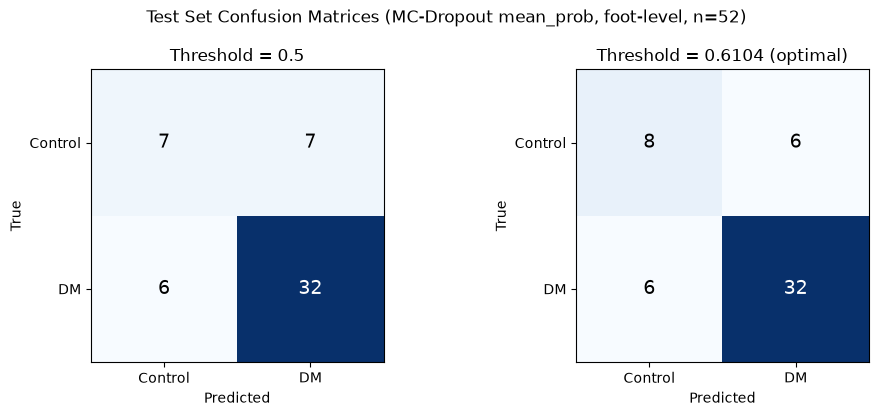

In [17]:
print("=== SECTION 6: Confusion Matrices + ROC Curve ===")

cm_05 = confusion_matrix(mc_labels, mc_preds_05)
cm_opt = confusion_matrix(mc_labels, mc_preds_opt)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
class_labels = ["Control", "DM"]
titles = [f"Threshold = 0.5", f"Threshold = {optimal_threshold:.4f} (optimal)"]

for ax, cm, title in zip(axes, [cm_05, cm_opt], titles):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(class_labels)
    ax.set_yticks([0, 1]); ax.set_yticklabels(class_labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title)
    thresh_color = cm.max() / 2
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                     color="white" if cm[i, j] > thresh_color else "black")

fig.suptitle("Test Set Confusion Matrices (MC-Dropout mean_prob, foot-level, n=52)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_confusion_matrices.png", dpi=150)
plt.show()


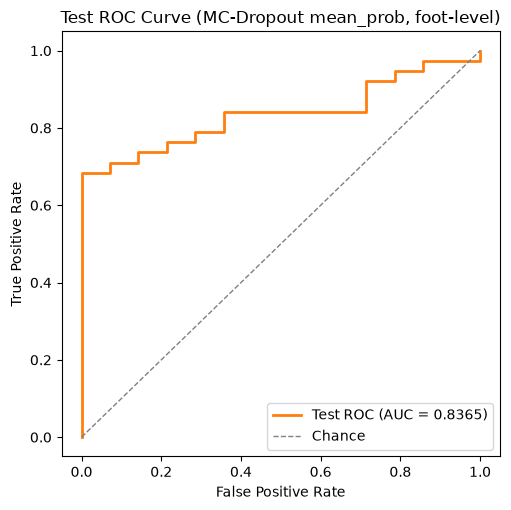

Test ROC-AUC (MC-Dropout mean_prob): 0.8365


In [18]:
fpr_test, tpr_test, _ = roc_curve(mc_labels, mc_mean_prob)
test_auc = roc_auc_score(mc_labels, mc_mean_prob)

plt.figure(figsize=(5.2, 5.2))
plt.plot(fpr_test, tpr_test, color="#ff7f0e", lw=2, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, linestyle="--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve (MC-Dropout mean_prob, foot-level)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_roc_curve.png", dpi=150)
plt.show()

print(f"Test ROC-AUC (MC-Dropout mean_prob): {test_auc:.4f}")


## Section 7 — Subject-Level Aggregation

The clinically meaningful unit is the **subject** (one diagnosis per person), not the
individual foot. Group the 52 test foot-level MC-Dropout `mean_prob` values by `subject_id`,
average the (typically 2) feet's `mean_prob` per subject, and confirm this produces exactly 26
rows (26 test subjects, matching Phase 5). Metrics are recomputed at both thresholds on these
averaged probabilities and compared against the foot-level numbers from Section 5.


In [19]:
print("=== SECTION 7: Subject-Level Aggregation ===")

foot_level_df = pd.DataFrame({
    "subject_id": mc_subject_id,
    "foot_side": mc_foot_side,
    "group": mc_group,
    "true_label": mc_labels,
    "mc_mean_prob": mc_mean_prob,
})

subject_level_df = (
    foot_level_df.groupby("subject_id", sort=False)
    .agg(
        group=("group", "first"),
        true_label=("true_label", "first"),
        mc_mean_prob=("mc_mean_prob", "mean"),
        n_feet=("mc_mean_prob", "size"),
    )
    .reset_index()
)

print(f"Foot-level test rows:                 {len(foot_level_df)}")
print(f"Subject-level rows after averaging:    {len(subject_level_df)}")
assert len(subject_level_df) == 26, f"Expected 26 test subjects, found {len(subject_level_df)}"
print("PASS: exactly 26 test subjects (matches Phase 5's split).")
print(f"Feet-per-subject counts: {subject_level_df['n_feet'].value_counts().to_dict()}")


=== SECTION 7: Subject-Level Aggregation ===
Foot-level test rows:                 52
Subject-level rows after averaging:    26
PASS: exactly 26 test subjects (matches Phase 5's split).
Feet-per-subject counts: {2: 26}


In [20]:
subj_labels = subject_level_df["true_label"].to_numpy()
subj_probs = subject_level_df["mc_mean_prob"].to_numpy()
subj_preds_05 = (subj_probs >= 0.5).astype(int)
subj_preds_opt = (subj_probs >= optimal_threshold).astype(int)

subject_metrics_05 = {
    "accuracy": float(accuracy_score(subj_labels, subj_preds_05)),
    "balanced_accuracy": float(balanced_accuracy_score(subj_labels, subj_preds_05)),
    "f1": float(f1_score(subj_labels, subj_preds_05, zero_division=0)),
    "roc_auc": float(roc_auc_score(subj_labels, subj_probs)),
}
subject_metrics_opt = {
    "accuracy": float(accuracy_score(subj_labels, subj_preds_opt)),
    "balanced_accuracy": float(balanced_accuracy_score(subj_labels, subj_preds_opt)),
    "f1": float(f1_score(subj_labels, subj_preds_opt, zero_division=0)),
    "roc_auc": subject_metrics_05["roc_auc"],
}

granularity_comparison_df = pd.DataFrame({
    "metric": [
        "roc_auc",
        "accuracy_0.5", "balanced_accuracy_0.5", "f1_0.5",
        "accuracy_optimal", "balanced_accuracy_optimal", "f1_optimal",
    ],
    "foot_level": [
        mc_metrics_05["roc_auc"],
        mc_metrics_05["accuracy"], mc_metrics_05["balanced_accuracy"], mc_metrics_05["f1"],
        mc_metrics_opt["accuracy"], mc_metrics_opt["balanced_accuracy"], mc_metrics_opt["f1"],
    ],
    "subject_level": [
        subject_metrics_05["roc_auc"],
        subject_metrics_05["accuracy"], subject_metrics_05["balanced_accuracy"], subject_metrics_05["f1"],
        subject_metrics_opt["accuracy"], subject_metrics_opt["balanced_accuracy"], subject_metrics_opt["f1"],
    ],
})

print("=== Foot-level (n=52) vs. Subject-level (n=26) metrics -- MC-Dropout, test set ===")
print(granularity_comparison_df.to_string(index=False))


=== Foot-level (n=52) vs. Subject-level (n=26) metrics -- MC-Dropout, test set ===
                   metric  foot_level  subject_level
                  roc_auc    0.836466       0.857143
             accuracy_0.5    0.750000       0.730769
    balanced_accuracy_0.5    0.671053       0.680451
                   f1_0.5    0.831169       0.810811
         accuracy_optimal    0.769231       0.730769
balanced_accuracy_optimal    0.706767       0.680451
               f1_optimal    0.842105       0.810811


**Which granularity is the headline result?**

Subject-level, since that is the actual clinical prediction target — a clinician diagnoses a
*patient*, not an isolated foot. Two feet from the same subject are correlated (same underlying
physiology and label), so foot-level metrics on n=52 effectively double-count n=26 independent
subjects and can look more stable than they really are. The subject-level numbers above (n=26,
averaged MC-Dropout probability per subject) are the number that should be reported as this
project's primary result.


## Section 8 — Uncertainty-Stratified ("Rejection Curve") Analysis

Using the foot-level `epistemic_uncertainty` values from Section 5, sort test samples by
epistemic uncertainty ascending (most confident first). For retained fractions of
`[100%, 90%, 75%, 50%, 25%]` (progressively rejecting the most uncertain samples), compute
accuracy at the optimal threshold on just the retained subset. A properly informative
uncertainty signal should show accuracy increasing (or at least not decreasing) as more
uncertain samples are excluded.


In [21]:
print("=== SECTION 8: Uncertainty-Stratified (Rejection Curve) Analysis ===")

order = np.argsort(mc_epistemic_uncertainty)  # ascending: most confident (lowest epistemic unc.) first
sorted_labels = mc_labels[order]
sorted_preds_opt = mc_preds_opt[order]

n_total = len(sorted_labels)
retained_fractions = [1.0, 0.9, 0.75, 0.5, 0.25]
rejection_rows = []
for frac in retained_fractions:
    n_keep = max(1, int(round(n_total * frac)))
    keep_labels = sorted_labels[:n_keep]
    keep_preds = sorted_preds_opt[:n_keep]
    acc = float(accuracy_score(keep_labels, keep_preds))
    rejection_rows.append({
        "retained_fraction": frac,
        "n_samples": n_keep,
        "accuracy_optimal_threshold": acc,
    })

rejection_df = pd.DataFrame(rejection_rows)
print(rejection_df.to_string(index=False))


=== SECTION 8: Uncertainty-Stratified (Rejection Curve) Analysis ===
 retained_fraction  n_samples  accuracy_optimal_threshold
              1.00         52                    0.769231
              0.90         47                    0.787234
              0.75         39                    0.871795
              0.50         26                    1.000000
              0.25         13                    1.000000


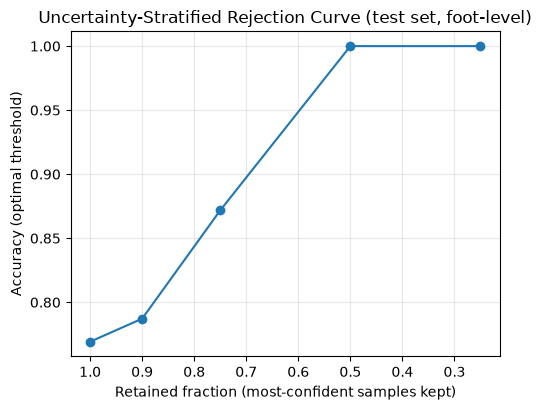

Accuracy strictly/weakly increases as uncertain samples are rejected: False


In [22]:
plt.figure(figsize=(5.2, 4.2))
plt.plot(rejection_df["retained_fraction"], rejection_df["accuracy_optimal_threshold"],
          marker="o", color="#1f77b4")
plt.gca().invert_xaxis()
plt.xlabel("Retained fraction (most-confident samples kept)")
plt.ylabel("Accuracy (optimal threshold)")
plt.title("Uncertainty-Stratified Rejection Curve (test set, foot-level)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "rejection_curve.png", dpi=150)
plt.show()

is_monotone_nondecreasing = bool(
    np.all(np.diff(rejection_df["accuracy_optimal_threshold"].to_numpy()[::-1]) >= -1e-9)
)
print(f"Accuracy strictly/weakly increases as uncertain samples are rejected: {is_monotone_nondecreasing}")


**Interpretation:** check the printed table and plot above for whether accuracy trends upward
as the most-uncertain samples are progressively excluded. With only 52 foot-level test
samples (and 26 independent subjects), the retained-25% bucket contains as few as ~13 samples —
any single flipped prediction moves that point by several percentage points. Treat this rejection
curve as a directional signal that the uncertainty estimate carries *some* information, not as a
precise, statistically robust characterization of the epistemic-uncertainty/accuracy
relationship.


## Section 9 — Error Analysis Table

Every foot-level test sample misclassified at the optimal threshold (using MC-Dropout
`mean_prob`), for later qualitative review when writing up results.


In [23]:
print("=== SECTION 9: Error Analysis (Misclassified at Optimal Threshold) ===")

misclassified_mask = mc_preds_opt != mc_labels

error_df = pd.DataFrame({
    "subject_id": mc_subject_id[misclassified_mask],
    "foot_side": mc_foot_side[misclassified_mask],
    "true_group": mc_group[misclassified_mask],
    "mc_mean_prob": mc_mean_prob[misclassified_mask],
    "mc_std_prob": mc_std_prob[misclassified_mask],
    "epistemic_uncertainty": mc_epistemic_uncertainty[misclassified_mask],
}).reset_index(drop=True)

print(f"{len(error_df)} / {len(mc_labels)} foot-level test samples misclassified "
      f"at threshold={optimal_threshold:.4f}")
print(error_df.to_string(index=False) if len(error_df) > 0 else "(no misclassified samples)")


=== SECTION 9: Error Analysis (Misclassified at Optimal Threshold) ===
12 / 52 foot-level test samples misclassified at threshold=0.6104
subject_id foot_side true_group  mc_mean_prob  mc_std_prob  epistemic_uncertainty
     CG012         L    Control      0.709443     0.138987               0.045051
     CG012         R    Control      0.650454     0.115148               0.028669
     CG037         L    Control      0.836262     0.082065               0.023091
     CG037         R    Control      0.791068     0.106373               0.032721
     CG045         L    Control      0.617640     0.149388               0.046427
     CG045         R    Control      0.761426     0.134167               0.046612
     DM028         R         DM      0.291333     0.107942               0.027509
     DM033         L         DM      0.210339     0.108985               0.034512
     DM033         R         DM      0.107775     0.104721               0.040680
     DM105         L         DM      0.1607

## Section 10 — Save Results

Three output files to `results/`:

1. `test_predictions.csv` — 52 rows, foot-level.
2. `subject_level_predictions.csv` — 26 rows, subject-level.
3. `test_evaluation_summary.json` — every metric, the confusion matrices, the rejection-curve
   table, the optimal threshold, and the checkpoint/config used, all in one place.


In [24]:
print("=== SECTION 10: Save Results ===")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. test_predictions.csv (foot-level, 52 rows) ---
test_predictions_df = pd.DataFrame({
    "subject_id": mc_subject_id,
    "foot_side": mc_foot_side,
    "group": mc_group,
    "true_label": mc_labels,
    "plain_prob": test_probs_plain,
    "mc_mean_prob": mc_mean_prob,
    "mc_std_prob": mc_std_prob,
    "predictive_entropy": mc_predictive_entropy,
    "expected_entropy": mc_expected_entropy,
    "epistemic_uncertainty": mc_epistemic_uncertainty,
    "pred_label_0.5": mc_preds_05,
    "pred_label_optimal": mc_preds_opt,
    "correct_0.5": (mc_preds_05 == mc_labels),
    "correct_optimal": (mc_preds_opt == mc_labels),
})
test_predictions_path = RESULTS_DIR / "test_predictions.csv"
test_predictions_df.to_csv(test_predictions_path, index=False)
assert test_predictions_df.shape[0] == 52
print(f"Saved {test_predictions_path}  -- shape {test_predictions_df.shape}")


=== SECTION 10: Save Results ===
Saved c:\workstation\3RD YEAR\Diabetic_Foot\results\test_predictions.csv  -- shape (52, 14)


In [25]:
# --- 2. subject_level_predictions.csv (26 rows) ---
subject_level_out_df = pd.DataFrame({
    "subject_id": subject_level_df["subject_id"],
    "group": subject_level_df["group"],
    "true_label": subject_level_df["true_label"],
    "mc_mean_prob": subject_level_df["mc_mean_prob"],
    "pred_label_0.5": subj_preds_05,
    "pred_label_optimal": subj_preds_opt,
    "correct_0.5": (subj_preds_05 == subj_labels),
    "correct_optimal": (subj_preds_opt == subj_labels),
})
subject_level_path = RESULTS_DIR / "subject_level_predictions.csv"
subject_level_out_df.to_csv(subject_level_path, index=False)
assert subject_level_out_df.shape[0] == 26
print(f"Saved {subject_level_path}  -- shape {subject_level_out_df.shape}")


Saved c:\workstation\3RD YEAR\Diabetic_Foot\results\subject_level_predictions.csv  -- shape (26, 8)


In [26]:
# --- 3. test_evaluation_summary.json ---
test_evaluation_summary = {
    "optimal_threshold": optimal_threshold,
    "foot_level_metrics": {
        "plain": {
            "threshold_0.5": {
                "roc_auc": test_metrics["roc_auc"],
                "accuracy": test_metrics["accuracy"],
                "balanced_accuracy": test_metrics["balanced_accuracy"],
                "f1": test_metrics["f1"],
            },
            "threshold_optimal": {
                "roc_auc": test_metrics["roc_auc"],
                "accuracy": plain_accuracy_optimal,
                "balanced_accuracy": plain_balanced_accuracy_optimal,
                "f1": plain_f1_optimal,
            },
        },
        "mc_dropout_T30": {
            "threshold_0.5": mc_metrics_05,
            "threshold_optimal": mc_metrics_opt,
        },
    },
    "subject_level_metrics": {
        "threshold_0.5": subject_metrics_05,
        "threshold_optimal": subject_metrics_opt,
    },
    "confusion_matrix": {
        "threshold_0.5": cm_05.tolist(),
        "threshold_optimal": cm_opt.tolist(),
    },
    "rejection_curve": rejection_df.to_dict(orient="records"),
    "checkpoint_path": str(CHECKPOINT_WEIGHTS_PATH),
    "config": PRIMARY_CONFIG,
}

test_evaluation_summary_path = RESULTS_DIR / "test_evaluation_summary.json"
with open(test_evaluation_summary_path, "w") as f:
    json.dump(test_evaluation_summary, f, indent=2, default=float)

print(f"Saved {test_evaluation_summary_path}")


Saved c:\workstation\3RD YEAR\Diabetic_Foot\results\test_evaluation_summary.json


## Section 11 — Final Summary


In [27]:
print("=" * 78)
print("=== SECTION 11: FINAL SUMMARY ===")
print("=" * 78)

print("\nHEADLINE RESULT (subject-level, optimal threshold, MC-Dropout, n=26 test subjects):")
print(f"  ROC-AUC            = {subject_metrics_opt['roc_auc']:.4f}")
print(f"  Balanced Accuracy  = {subject_metrics_opt['balanced_accuracy']:.4f}")
print(f"  F1                 = {subject_metrics_opt['f1']:.4f}")
print(f"  (optimal threshold = {optimal_threshold:.4f}, selected on VAL only, per Section 3)")

print("\n" + "=" * 78)
print("*** TEST SET WAS TOUCHED EXACTLY ONCE IN THIS NOTEBOOK. ***")
print("*** Do NOT re-tune the model, threshold, or hyperparameters based on the")
print("*** results above. Any further changes must be validated on train/val")
print("*** only (repeating Phases 8-10), followed by exactly one fresh Phase 11")
print("*** re-run as the new final check. ***")
print("=" * 78)

print("\nSaved result files:")
for p in [test_predictions_path, subject_level_path, test_evaluation_summary_path]:
    print(f"  - {p}  (exists: {p.exists()})")

print("\nPhase 12's ablation notebook will reuse this exact evaluate() / mc_dropout_predict()")
print("procedure on this SAME test set, for a fair comparison against this primary result.")

issues_found = []
if roc_auc_diff > TOLERANCE:
    issues_found.append(
        f"Section 2 val-reconfirmation ROC-AUC differed from Phase 10's recorded value by "
        f"{roc_auc_diff:.6f} (tolerance {TOLERANCE})."
    )

if len(issues_found) == 0:
    print("\nIssues found: 0 issues found.")
else:
    print(f"\nIssues found ({len(issues_found)}):")
    for issue in issues_found:
        print(f"  - {issue}")


=== SECTION 11: FINAL SUMMARY ===

HEADLINE RESULT (subject-level, optimal threshold, MC-Dropout, n=26 test subjects):
  ROC-AUC            = 0.8571
  Balanced Accuracy  = 0.6805
  F1                 = 0.8108
  (optimal threshold = 0.6104, selected on VAL only, per Section 3)

*** TEST SET WAS TOUCHED EXACTLY ONCE IN THIS NOTEBOOK. ***
*** Do NOT re-tune the model, threshold, or hyperparameters based on the
*** results above. Any further changes must be validated on train/val
*** only (repeating Phases 8-10), followed by exactly one fresh Phase 11
*** re-run as the new final check. ***

Saved result files:
  - c:\workstation\3RD YEAR\Diabetic_Foot\results\test_predictions.csv  (exists: True)
  - c:\workstation\3RD YEAR\Diabetic_Foot\results\subject_level_predictions.csv  (exists: True)
  - c:\workstation\3RD YEAR\Diabetic_Foot\results\test_evaluation_summary.json  (exists: True)

Phase 12's ablation notebook will reuse this exact evaluate() / mc_dropout_predict()
procedure on this SAME

---

## 🔒 REMINDER: TEST SET TOUCHED ONCE — DO NOT RE-TUNE BASED ON THESE RESULTS 🔒

If anything above suggests the model, threshold, or hyperparameters need to change, make those
changes and validate them using **only train/val** (repeating Phases 8–10), then run **one
fresh Phase 11 re-run** as the new final check. This notebook, as executed, stands as the single
unbiased test-set estimate for the primary configuration.
